# Proyecto 3: Mejorando algoritmos con CUDA
**CC3069 Computación Paralela y Distribuida — Universidad del Valle de Guatemala, semestre II-2026**

**Equipo:** Daniel Oswaldo Juárez Herrera · Humberto Alexander de la Cruz · Nicolle Alexandra Gordillo

Este notebook acelera el **Laboratorio 3 de Data Science (reconocimiento del alfabeto ASL con CNN)** separando el flujo en dos fases con hardware distinto:

| Fase | Qué hace | Dónde corre | Cómo |
|---|---|---|---|
| **1. Preparación de datos** | leer, decodificar y redimensionar 23,200 JPEG | **CPU, varios núcleos** | `ProcessPoolExecutor` + `SharedMemory` (`src/preparacion.py`) |
| **2. Entrenamiento e inferencia** | convoluciones, productos de matrices, retropropagación, Adam | **GPU (CUDA)** | PyTorch + cuDNN (`src/modelos.py`, `src/entrenamiento.py`) y kernels propios en Numba CUDA (`src/kernels_cuda.py`) |

La línea base es la solución original: Keras/TensorFlow en CPU (`src/modelos_keras.py`, copia fiel de `lab3_original/Lab3_Final.ipynb`).

**Cómo está organizado:** las secciones 1 a 6 siguen los pasos del enunciado. Las mediciones repetidas (varias corridas por configuración) las hace `python -m src.correr_experimentos` y quedan en `resultados/`. Este notebook las analiza y además ejecuta en vivo cada fase para dejar evidencia.

In [1]:
# Configuración: rutas, dependencias y hardware disponible
import os, sys, time, json, inspect, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ = os.path.abspath('.')
sys.path.insert(0, RAIZ)
os.environ.setdefault('ASL_DATASET_PATH', os.path.join(RAIZ, 'asl_alphabet_train'))

from src import preparacion as prep
from src import analisis as an
from src.monitor import MonitorRecursos
from src.benchmark import info_sistema

an.estilo()
pd.set_option('display.precision', 3)
print(json.dumps(info_sistema(), indent=1, ensure_ascii=False))
print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)

{
 "python": "3.13.7",
 "so": "Windows-11-10.0.26200-SP0",
 "cpu": "Intel64 Family 6 Model 140 Stepping 2, GenuineIntel",
 "nucleos_fisicos": 4,
 "nucleos_logicos": 8,
 "ram_gb": 16.9,
 "torch": "2.11.0+cu128",
 "cuda_torch": "12.8",
 "cudnn": 91900,
 "gpu": "NVIDIA GeForce MX450",
 "hilos_torch_cpu": 4
}
Sat Nov 14 08:07:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.60                 KMD Version: 610.60        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeF

## 1. Análisis de la solución secuencial existente

El Lab 3 es un notebook de 57 celdas. Sus partes principales son:

| Parte | Celdas del Lab 3 | Función |
|---|---|---|
| Carga del dataset | 1 | Localiza `asl_alphabet_train/` y lista las 29 clases. |
| EDA (Ejercicios 1–2) | 2–7 | Muestra ejemplos, brillo promedio por clase y letras parecidas. |
| Preprocesamiento (Ejercicio 3) | 8–9 | Submuestrea 800 imágenes por clase, las redimensiona a 64×64 y normaliza a [0,1]. |
| Partición | 11 | Divide 70/15/15 de forma estratificada con semilla 42. |
| Modelos CNN (Ejercicio 4) | 12–16 | CNN Base y CNN Profunda en Keras, entrenadas con Adam y EarlyStopping. |
| Red densa (Ejercicio 5) | 17–18 | MLP de referencia (no llegó a aprender: 3.45%). |
| Evaluación | 19–25 | Exactitud en prueba, curvas, matriz de confusión y reporte por clase. |
| Algoritmos clásicos (Ejercicio 6) | 26–33 | Escala de grises + PCA; Random Forest, SVM y KNN con scikit-learn. |
| Aumento de datos (Ejercicio 7) | 34–45 | Capas de aumento dentro del modelo; reentrenamiento de ambas CNN y ablación con espejo. |
| Fotos propias (Ejercicio 8) | 46–52 | Prueba fuera de dominio con 15 fotos del equipo. |
| Sesgo (Ejercicio 9) | 53–55 | Análisis de vecinos más cercanos y discusión. |

El trabajo pesado está en dos lugares: **el preprocesamiento** (decodificar miles de JPEG) y **el entrenamiento de las CNN** (Ejercicios 4 y 7), que en la máquina original tomó 52 de los ~60 minutos del notebook.

### 1.1 Operaciones del programa, de la imagen al resultado

| No. | Operación identificada | Descripción de su funcionamiento |
|---|---|---|
| 1 | Listado de archivos | `os.listdir` por cada una de las 29 carpetas (3,000 archivos cada una). |
| 2 | Submuestreo | `random.sample` elige 800 archivos por clase: 23,200 imágenes. |
| 3 | Lectura del archivo | Lee los bytes del JPEG del disco (~15 KB cada uno). |
| 4 | Decodificación JPEG | Pillow descomprime cada imagen a 200×200×3 píxeles (Huffman + IDCT por bloques de 8×8). |
| 5 | Redimensión | `resize((64, 64))` con filtro bicúbico: cada píxel de salida combina una vecindad del original. |
| 6 | Normalización | Convierte a `float32` y divide entre 255; escribe la imagen en el tensor `X` (23,200×64×64×3, 1.14 GB). |
| 7 | Partición estratificada | `train_test_split` sobre índices: 16,240 / 3,480 / 3,480. |
| 8 | Barajado y loteo | En cada época se barajan los índices y se toman lotes de 64 imágenes (254 lotes por época). |
| 9 | Convolución 3×3 + ReLU | Cada valor de salida es una suma de 9·C_in productos más un sesgo. Es la operación dominante (ver 1.2). |
| 10 | Max-pooling 2×2 | Reduce a la mitad el alto y el ancho tomando el máximo de cada ventana. |
| 11 | Capas densas | Productos de matrices: 8192→128 (Base) o 128→256 (Profunda), y luego →29. |
| 12 | BatchNorm / Dropout | (Profunda) normaliza por canal; apaga activaciones al azar durante el entrenamiento. |
| 13 | Softmax + entropía cruzada | Convierte logits en probabilidades y calcula la pérdida del lote. |
| 14 | Retropropagación | Gradientes de todas las capas en orden inverso; cuesta ~2 veces la propagación hacia adelante. |
| 15 | Actualización Adam | Actualiza cada parámetro con sus momentos (1.1 millones de parámetros en la CNN Base). |
| 16 | Validación por época | Propagación hacia adelante sobre 3,480 imágenes al final de cada época. |
| 17 | Inferencia y métricas | `predict` sobre prueba, `argmax`, exactitud, matriz de confusión. |

In [2]:
# 1.2 Cuántas veces se repite cada operación (conteos exactos para esta configuración)
def macs_conv(lado, c_in, c_out):
    return lado * lado * c_out * 9 * c_in

capas = {
    'CNN Base': [('Conv 3→32 @64×64', macs_conv(64, 3, 32)), ('Conv 32→64 @32×32', macs_conv(32, 32, 64)),
                 ('Conv 64→128 @16×16', macs_conv(16, 64, 128)), ('Densa 8192→128', 8192 * 128),
                 ('Densa 128→29', 128 * 29)],
    'CNN Profunda': [('Conv 3→32', macs_conv(64, 3, 32)), ('Conv 32→32', macs_conv(64, 32, 32)),
                     ('Conv 32→64', macs_conv(32, 32, 64)), ('Conv 64→64', macs_conv(32, 64, 64)),
                     ('Conv 64→128', macs_conv(16, 64, 128)), ('Conv 128→128', macs_conv(16, 128, 128)),
                     ('Densa 128→256', 128 * 256), ('Densa 256→29', 256 * 29)],
}
N_TRAIN, LOTE = 16_240, 64
for modelo, lista in capas.items():
    total = sum(m for _, m in lista)
    tabla_capas = pd.DataFrame([(n, m / 1e6, m / total) for n, m in lista],
                               columns=['Capa', 'MACs por imagen (millones)', '% del total'])
    print(f"{modelo}: {total / 1e6:.1f} M multiplicaciones-suma por imagen hacia adelante; "
          f"~{3 * 2 * total * N_TRAIN / 1e12:.1f} TFLOP por época (adelante + atrás ≈ 3×)")
    display(tabla_capas.style.format({'MACs por imagen (millones)': '{:.2f}', '% del total': '{:.1%}'}))

CNN Base: 42.3 M multiplicaciones-suma por imagen hacia adelante; ~4.1 TFLOP por época (adelante + atrás ≈ 3×)


,Capa,MACs por imagen (millones),% del total
0,Conv 3→32 @64×64,3.54,8.4%
1,Conv 32→64 @32×32,18.87,44.6%
2,Conv 64→128 @16×16,18.87,44.6%
3,Densa 8192→128,1.05,2.5%
4,Densa 128→29,0.00,0.0%


CNN Profunda: 154.6 M multiplicaciones-suma por imagen hacia adelante; ~15.1 TFLOP por época (adelante + atrás ≈ 3×)


,Capa,MACs por imagen (millones),% del total
0,Conv 3→32,3.54,2.3%
1,Conv 32→32,37.75,24.4%
2,Conv 32→64,18.87,12.2%
3,Conv 64→64,37.75,24.4%
4,Conv 64→128,18.87,12.2%
5,Conv 128→128,37.75,24.4%
6,Densa 128→256,0.03,0.0%
7,Densa 256→29,0.01,0.0%


| Operación repetitiva | Datos que procesa | Cantidad de repeticiones |
|---|---|---|
| Lectura + decodificación + redimensión | un JPEG de 200×200×3 | **23,200** (una por imagen seleccionada) |
| Normalización (÷255) | 12,288 valores por imagen | 23,200 imágenes = **285 millones** de divisiones |
| Paso de entrenamiento (adelante + atrás + Adam) | un lote de 64×64×64×3 | **254 por época** × 20–30 épocas × 4 modelos |
| Multiplicación-suma de la convolución | ventana 3×3×C_in × filtro | **42.3 M por imagen** (Base) / **154.6 M** (Profunda), ×16,240 imágenes ×3 (adelante y atrás) por época |
| Max-pooling | ventanas 2×2 | 3 capas × 64 imágenes × (32²·32 + 16²·64 + 8²·128) salidas por lote |
| Actualización de Adam | 1,145,693 parámetros (Base) / 327,933 (Profunda) | una vez por lote: **254 × parámetros** por época |
| Validación | 3,480 imágenes de validación | una vez por época |

**Lectura de las tablas:** el 89% del cómputo de la CNN Base está en dos convoluciones y el 98% del de la Profunda en sus seis convoluciones. Son millones de multiplicaciones-suma **independientes entre sí** (cada valor de salida se calcula sin esperar a los demás), que es exactamente el tipo de trabajo para el que existe una GPU. La preparación, en cambio, son 23,200 tareas independientes y **pesadas en lógica** (descompresión JPEG, ramas, acceso a disco), que encajan mejor en núcleos de CPU.

## 2. Medición del tiempo de ejecución secuencial

**Procedimiento:**
1. **Mismo hardware para todo:** laptop con Intel Core i7-11390H (4 núcleos / 8 hilos, AVX-512), 16 GB de RAM y NVIDIA GeForce MX450 (2 GB). Conectada a la corriente, con el modo de energía de Windows en **"Mejor rendimiento"**. Los tiempos del Lab 3 original se midieron en otra computadora y **no** se comparan directamente.
2. **Mismos datos:** el mismo subconjunto de 23,200 imágenes en todas las corridas. Para eso se corrigió la semilla del Lab 3 (ver `lab3_original/README.md`).
3. **Caché caliente:** antes de medir la preparación se leen una vez todos los archivos. El dataset está en una carpeta de OneDrive, donde la primera lectura es mucho más lenta.
4. **Repeticiones:** 5 corridas de la preparación y 3 de cada entrenamiento. Se reportan la media y la desviación estándar.
5. **Mismo trabajo:** para comparar dispositivos, cada entrenamiento corre un **número fijo de 3 épocas, sin EarlyStopping**. La primera época se reporta aparte (incluye compilación del grafo / autoajuste de cuDNN); el costo en régimen estable es la **media de las épocas 2 y 3**.
6. **Pausa de 60 s entre corridas** para que todas partan de un estado térmico parecido.
7. **Línea base de extremo a extremo:** además se ejecutó el notebook completo del Lab 3 (con la semilla corregida) en esta misma máquina: `resultados/lab3_reproducible_ejecutado.ipynb`.

In [3]:
# 2.1 Lab 3 completo ejecutado en ESTA máquina (Keras/TF en CPU) vs. la máquina original
lab3_aqui = an.leer_lab3_ejecutado().set_index('modelo')
lab3_original = an.leer_lab3_ejecutado(os.path.join(RAIZ, 'lab3_original', 'Lab3_Final.ipynb')).set_index('modelo')
comparacion = pd.DataFrame({
    'Épocas': lab3_aqui['epocas'],
    'Minutos (esta laptop)': lab3_aqui['minutos'],
    'Minutos (máquina original)': lab3_original['minutos'],
    'Exactitud prueba (esta laptop)': lab3_aqui['test_acc'],
    'Exactitud prueba (original)': lab3_original['test_acc'],
})
display(comparacion.style.format({'Minutos (esta laptop)': '{:.1f}', 'Minutos (máquina original)': '{:.1f}',
                                  'Exactitud prueba (esta laptop)': '{:.2%}', 'Exactitud prueba (original)': '{:.2%}'}))
print(f"Entrenamiento total de los modelos en CPU, esta laptop: {lab3_aqui['minutos'].sum():.1f} min")

,Épocas,Minutos (esta laptop),Minutos (máquina original),Exactitud prueba (esta laptop),Exactitud prueba (original)
modelo,,,,,
CNN Base,20,10.0,3.4,98.33%,98.62%
CNN Profunda,13,31.9,11.7,97.56%,98.36%
Red Densa (MLP),7,1.6,0.8,3.45%,3.45%
CNN Base + Aug,30,18.7,5.8,99.17%,99.25%
CNN Profunda + Aug,19,50.2,30.8,99.40%,99.31%
CNN Base + Espejo,30,18.2,6.3,97.64%,96.38%


Entrenamiento total de los modelos en CPU, esta laptop: 130.6 min


In [4]:
# 2.2 Tiempos secuenciales medidos con repeticiones
res_prep = an.resumen_preparacion()
res_train = an.resumen_entrenamiento()

sec = res_prep[res_prep.variante == 'secuencial'].iloc[0]
print(f"Preparación secuencial de 23,200 imágenes: {sec.media_s:.2f} ± {sec.std_s:.2f} s "
      f"({sec.reps} corridas) → {sec.imagenes_por_s:.0f} imágenes/s")

base_cpu = res_train[res_train.framework == 'keras'][
    ['modelo', 'reps', 'primera_epoca_s', 'epoca_s', 'epoca_std', 'inferencia_s', 'test_acc', 'cpu_pct', 'gpu_pct']]
display(base_cpu.rename(columns={
    'reps': 'Corridas', 'primera_epoca_s': '1ª época (s)', 'epoca_s': 'Época estable (s)',
    'epoca_std': 'Desv. (s)', 'inferencia_s': 'Inferencia 3,480 img (s)',
    'test_acc': 'Exactitud tras 3 épocas', 'cpu_pct': 'CPU media (%)', 'gpu_pct': 'GPU media (%)'})
    .style.format(precision=2).format({'Exactitud tras 3 épocas': '{:.2%}'}))

Preparación secuencial de 23,200 imágenes: 24.90 ± 5.09 s (5 corridas) → 932 imágenes/s


,modelo,Corridas,1ª época (s),Época estable (s),Desv. (s),"Inferencia 3,480 img (s)",Exactitud tras 3 épocas,CPU media (%),GPU media (%)
0,CNN Base,3,35.145333,34.764333,3.622289,2.567467,90.55%,93.700000,0.000000
4,CNN Profunda,3,219.447667,241.341000,1.323610,12.386333,75.06%,97.466667,0.000000
7,CNN Base + Aug,3,41.915333,39.490333,4.337338,2.199267,70.80%,85.366667,0.000000
9,CNN Profunda + Aug,3,242.989667,242.530000,21.639316,15.453767,73.48%,97.300000,0.000000


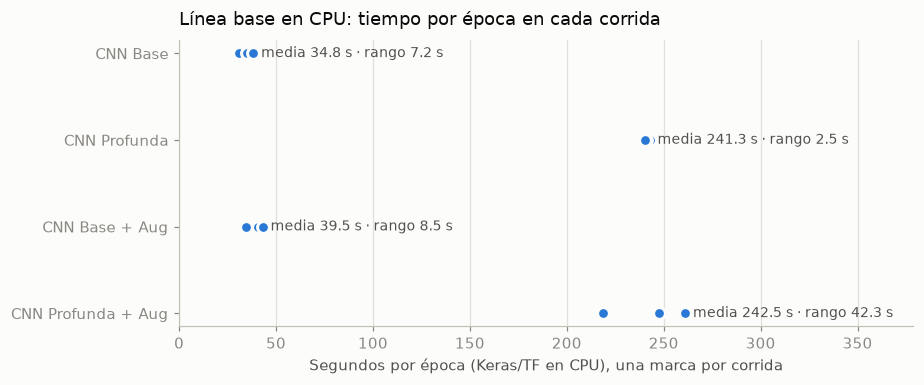

In [5]:
# 2.3 Variabilidad entre corridas de la línea base en CPU
crudo = pd.read_csv(os.path.join(an.RESULTADOS, 'entrenamiento.csv'))
keras_crudo = crudo[crudo.framework == 'keras']
fig, eje = plt.subplots(figsize=(8.5, 3.6))
for i, m in enumerate(an.ORDEN_MODELOS):
    v = keras_crudo.loc[keras_crudo.modelo == m, 't_epoca_media_sin_1ra_s']
    eje.scatter(v, [i] * len(v), s=60, color=an.CONFIGS[('keras', 'cpu')][1],
                edgecolor=an.SUPERFICIE, linewidth=2, zorder=3)
    eje.text(v.max() + 4, i, f'media {v.mean():.1f} s · rango {v.max() - v.min():.1f} s',
             va='center', fontsize=9, color=an.TINTA_SUAVE)
eje.set_yticks(range(4), an.ORDEN_MODELOS); eje.invert_yaxis()
eje.set_xlabel('Segundos por época (Keras/TF en CPU), una marca por corrida')
eje.set_title('Línea base en CPU: tiempo por época en cada corrida'); eje.grid(axis='y', visible=False)
eje.set_xlim(0, keras_crudo['t_epoca_media_sin_1ra_s'].max() * 1.45)
plt.tight_layout(); an.guardar(fig, '02_variabilidad_cpu'); plt.show()

### 2.4 Factores que influyen en el rendimiento secuencial

* **La CPU.** El i7-11390H es un procesador de laptop de 35 W con 4 núcleos. Esta laptop entrena entre 2.6 y 3.2 veces más lento por época que la máquina donde se hizo el Lab 3 (tabla 2.1). Con la laptop conectada a la corriente, el tiempo por época se mantuvo estable durante las 2 horas del Lab 3 completo (Base ~29 s, Profunda ~147 s). En cambio, en las mediciones de 3 épocas de la CNN Profunda el control térmico de Intel (DPTF) frenó el CPU tras ~2 minutos de carga sostenida, y la época subió a ~240 s (ver la nota bajo la tabla 6.1).
* **La memoria RAM.** Fue el factor que más alteró las mediciones. Una primera medición de la línea base corrió con 14–15.8 GB de RAM ocupados (de 16) y sus épocas tardaron 1.8 veces más. Solo el dataset en memoria ocupa 1.14 GB en `float32`. Se descartó y se repitió con la memoria libre (`resultados/descartado/`).
* **El modo de energía de Windows.** Un segundo intento corrió en modo "Mejor eficiencia energética": el CPU estaba ocupado al 100 %, pero a ~27 % de su frecuencia máxima, y las épocas tardaron hasta 4 veces más. También se descartó. Las mediciones válidas son en modo "Mejor rendimiento".
* **TensorFlow ya es paralelo en CPU.** La línea base "secuencial" no corre en un solo hilo: TensorFlow usa oneDNN con instrucciones AVX-512 y los 8 hilos lógicos (CPU media ~90% durante el entrenamiento). La GPU compite contra una CPU que ya trabaja en paralelo, no contra un bucle de Python.
* **Disco y OneDrive.** La primera lectura de los 23,200 archivos desde OneDrive tarda mucho más que las siguientes; por eso la caché se calienta antes de medir.
* **El tamaño del modelo.** La CNN Profunda tiene 3.5 veces menos parámetros que la Base, pero 3.7 veces más operaciones (convoluciones dobles sobre mapas grandes): el tiempo sigue a las operaciones, no a los parámetros.
* **El aumento de datos** agrega las transformaciones geométricas de cada lote al costo de cada paso.

## 3. Identificación de oportunidades de paralelización

| Operación | ¿Paralelizable? | Dónde | Justificación |
|---|---|---|---|
| Lectura, decodificación y redimensión de JPEG | Sí, por imagen (23,200 tareas independientes) | **CPU, varios procesos** | Decodificar JPEG es lógica con muchas ramas (Huffman) y acceso a disco, para lo que un núcleo de CPU es mejor. En Python los hilos no escalan por el GIL, así que se usan procesos. |
| Normalización ÷255 | Sí, por elemento | CPU (dentro del mismo proceso) | Es trivial y va pegada a la decodificación: mandarla a la GPU costaría más en transferencia que lo que ahorra. |
| Partición y barajado | Poco trabajo | CPU | Opera sobre índices; es microsegundos. |
| Convoluciones (adelante y atrás) | Sí, por cada valor de salida (millones por lote) | **GPU** | Son el 89–98% del cómputo; operaciones aritméticas idénticas e independientes, ideales para miles de hilos. |
| Capas densas | Sí, producto de matrices | **GPU** | Productos de matrices en baldosas, con reutilización en memoria compartida. |
| ReLU, pooling, dropout, BatchNorm | Sí, por elemento o por canal | **GPU** | Elemento a elemento; se ejecutan donde ya están los datos para no transferirlos. |
| Softmax + pérdida | Sí, por imagen | **GPU** | 64 hilos por lote; los datos ya están en la GPU. |
| Actualización de Adam | Sí, por parámetro | **GPU** | 1.1 M de actualizaciones independientes por paso. |
| Aumento de datos | Sí, por imagen | **GPU** | En Keras las capas de aumento son parte del modelo; se conserva ese diseño y corren en la GPU como transformaciones afines por lote. |
| Validación e inferencia | Sí | **GPU** | Solo propagación hacia adelante; misma lógica que el entrenamiento. |
| Algoritmos clásicos (Random Forest, SVM, KNN) | — | CPU (sin cambios) | scikit-learn no usa GPU y cuML (RAPIDS) no está disponible para Windows; quedan fuera del alcance. |

**La idea central:** cada tipo de trabajo va al procesador que lo hace mejor. La CPU tiene pocos núcleos rápidos, buenos para lógica con ramas y E/S, y la GPU tiene cientos de núcleos simples, buenos para la misma operación aritmética sobre millones de datos. Las imágenes solo cruzan a la GPU ya convertidas en tensores, en lotes de 64 (3 MB por lote).

## 4. Diseño del algoritmo paralelo

### 4.1 Fase 1 en CPU: procesos con memoria compartida

```
proceso principal                                procesos trabajadores (8)
──────────────────                               ─────────────────────────
selecciona 23,200 rutas (semilla fija)
reserva SharedMemory de 1.14 GB  ───────────────►  cada uno se conecta al bloque por su nombre
divide en 32 tramos contiguos ──── tramo k ─────►  decodifica + redimensiona + ÷255
                                                   escribe X[inicio:fin] directo en el bloque
espera los 32 resultados (pid, inicio, n) ◄──────  devuelve solo 3 enteros
copia el bloque a un arreglo normal
```

* **Procesos, no hilos:** cada proceso tiene su propio intérprete y su propio GIL.
* **4 tramos por proceso (32 en total)** para balancear la carga: el que termina antes toma otro tramo.
* **Memoria compartida:** sin ella, cada proceso devolvería su parte serializada (pickle) y se copiarían 1.14 GB entre procesos. Así, cada proceso devuelve solo 3 números.

### 4.2 Fase 2 en GPU con PyTorch + cuDNN

* Los tensores de entrenamiento quedan en la RAM del CPU en memoria *pinned*. Cada lote de 64 imágenes (3 MB) se copia a la GPU por DMA; el conjunto completo (~800 MB) cabría en los 2 GB de la MX450, pero dejaría poco margen para activaciones y espacio de trabajo de cuDNN.
* cuDNN elige el algoritmo de convolución más rápido para cada forma de capa (`cudnn.benchmark = True`).
* La pérdida y los aciertos se acumulan en la GPU y se leen una vez por época: leerlos en cada lote obligaría a sincronizar CPU y GPU 254 veces por época.

### 4.3 Kernels propios en CUDA Python (Numba): hilos, bloques y grid

Para diseñar explícitamente el reparto del trabajo, la CNN Base completa (adelante, atrás y Adam) se implementó con kernels propios en `src/kernels_cuda.py`. La celda siguiente calcula la configuración real de lanzamiento de cada kernel para un lote de 64 imágenes.

In [6]:
from src import kernels_cuda as kc
N = 64
filas = []
for i, ((ci, co), lado) in enumerate(zip(kc.CAPAS_CONV, (64, 32, 16)), 1):
    P = N * lado * lado
    filas += [
        (f'conv{i} adelante', 'k_conv_gemm_rt', f'({-(-P // kc.BM)}, {-(-co // kc.BN)})', '8×16 = 128',
         '4×4 salidas por hilo', -(-P // kc.BM) * -(-co // kc.BN) * 128),
        (f'conv{i} grad. pesos', 'k_conv_gemm_pesos',
         f'({-(-co // 16)}, {-(-9 * ci // 16)}, {-(-P // 4096)})', '16×16 = 256',
         'split-K: 4,096 píxeles por bloque', -(-co // 16) * -(-9 * ci // 16) * -(-P // 4096) * 256),
    ]
    if i > 1:
        filas.append((f'conv{i} grad. entrada', 'k_conv_gemm_rt (pesos volteados)',
                      f'({-(-P // kc.BM)}, {-(-ci // kc.BN)})', '8×16 = 128', '4×4 salidas por hilo',
                      -(-P // kc.BM) * -(-ci // kc.BN) * 128))
    Pp = P // 4
    filas.append((f'pool{i} adelante', 'k_maxpool_forward', f'({-(-co // 32)}, {-(-Pp // 8)})', '32×8 = 256',
                  '1 salida por hilo', -(-co // 32) * -(-Pp // 8) * 256))
filas += [('densa 8192→128', 'k_matmul', '(8, 4)', '16×16 = 256', 'baldosas 16×16 en memoria compartida', 8 * 4 * 256),
          ('softmax + pérdida', 'k_softmax_entropia', '(1,)', '64', '1 imagen por hilo', 64),
          ('Adam (conv3_w)', 'k_adam', f'({-(-73728 // 256)},)', '256', '1 parámetro por hilo', 73728)]
display(pd.DataFrame(filas, columns=['Operación', 'Kernel', 'Grid (bloques)', 'Hilos por bloque',
                                     'Trabajo por hilo', 'Hilos lanzados'])
        .style.format({'Hilos lanzados': '{:,}'}))

,Operación,Kernel,Grid (bloques),Hilos por bloque,Trabajo por hilo,Hilos lanzados
0,conv1 adelante,k_conv_gemm_rt,"(4096, 1)",8×16 = 128,4×4 salidas por hilo,"524,288"
1,conv1 grad. pesos,k_conv_gemm_pesos,"(2, 2, 64)",16×16 = 256,"split-K: 4,096 píxeles por bloque","65,536"
2,pool1 adelante,k_maxpool_forward,"(1, 8192)",32×8 = 256,1 salida por hilo,"2,097,152"
3,conv2 adelante,k_conv_gemm_rt,"(1024, 2)",8×16 = 128,4×4 salidas por hilo,"262,144"
4,conv2 grad. pesos,k_conv_gemm_pesos,"(4, 18, 16)",16×16 = 256,"split-K: 4,096 píxeles por bloque","294,912"
5,conv2 grad. entrada,k_conv_gemm_rt (pesos volteados),"(1024, 1)",8×16 = 128,4×4 salidas por hilo,"131,072"
6,pool2 adelante,k_maxpool_forward,"(2, 2048)",32×8 = 256,1 salida por hilo,"1,048,576"
7,conv3 adelante,k_conv_gemm_rt,"(256, 4)",8×16 = 128,4×4 salidas por hilo,"131,072"
8,conv3 grad. pesos,k_conv_gemm_pesos,"(8, 36, 4)",16×16 = 256,"split-K: 4,096 píxeles por bloque","294,912"
9,conv3 grad. entrada,k_conv_gemm_rt (pesos volteados),"(256, 2)",8×16 = 128,4×4 salidas por hilo,"65,536"


**Decisiones de diseño de los kernels (detalle en los docstrings de `src/kernels_cuda.py`):**

1. **Convolución como producto de matrices implícito (*implicit GEMM*).** La convolución se reescribe como `salida(P×C_out) = A(P×9·C_in) · W(9·C_in×C_out)`, con P = imágenes × alto × ancho, donde cada fila de A son los 3×3×C_in vecinos de un píxel. A nunca se guarda en memoria (ocuparía 9 veces la entrada): cada bloque calcula su parte al cargarla en memoria compartida. Los pesos en formato HWIO de Keras ya tienen exactamente la forma de W.
2. **Memoria compartida.** Cada bloque carga baldosas de A y de W en memoria compartida (`cuda.shared.array`) y cada valor se reutiliza 16–64 veces antes de volver a la memoria global.
3. **Register tiling.** En `k_conv_gemm_rt` cada hilo acumula 4×4 salidas en registros: por cada valor leído de memoria compartida hace 4 multiplicaciones-suma en lugar de 1.
4. **Split-K con atomics** para el gradiente de los pesos: la reducción recorre hasta 262,144 píxeles y la salida es pequeña (27×32 en la primera capa), así que la suma se reparte en trozos (`blockIdx.z`) que se combinan con `cuda.atomic.add`.
5. **El gradiente de la entrada es otra convolución** con los pesos volteados 180° y transpuestos (`k_voltear_pesos`), así que reutiliza el mismo kernel.
6. **Sin atomics en el pooling:** las ventanas 2×2 no se solapan, así que la retropropagación es un *gather* (un hilo por píxel de entrada) y se fusiona con la ReLU.
7. **Solo float32:** la MX450 calcula float64 a 1/32 de la velocidad de float32. Todas las constantes son `float32` para que Numba no promueva a float64.
8. **Kernels cortos:** en Windows (modo WDDM) un kernel de más de ~2 s reinicia el controlador (TDR); por eso se trabaja lote por lote.
9. **Doble buffer y copias asíncronas:** la CPU arma el lote i+1 en memoria *pinned* mientras la GPU calcula el lote i.

## 5. Implementación

### 5.1 Fase 1 — preparación en CPU: secuencial contra paralela (ejecución en vivo)

El código de ambas versiones (`src/preparacion.py`):

In [7]:
print(inspect.getsource(prep.preparar_secuencial))
print(inspect.getsource(prep._trabajador))
print(inspect.getsource(prep.preparar_paralelo))

def preparar_secuencial(rutas: list[str]) -> np.ndarray:
    """Procesa las imágenes una por una en el proceso actual."""
    X = np.empty((len(rutas), *NUEVA_RESOLUCION, CANALES), dtype=np.float32)
    for i, ruta in enumerate(rutas):
        X[i] = cargar_imagen(ruta)
    return X

def _trabajador(nombre_memoria: str, forma: tuple, inicio: int,
                rutas: list[str]) -> tuple[int, int, int]:
    """Procesa un tramo contiguo de imágenes y lo escribe en la memoria compartida.

    Devuelve (pid, inicio, cantidad) para poder registrar qué proceso hizo qué.
    """
    memoria = shared_memory.SharedMemory(name=nombre_memoria)
    try:
        X = np.ndarray(forma, dtype=np.float32, buffer=memoria.buf)
        for desplazamiento, ruta in enumerate(rutas):
            X[inicio + desplazamiento] = cargar_imagen(ruta)
        del X  # liberar la vista antes de cerrar el bloque
    finally:
        memoria.close()
    return os.getpid(), inicio, len(rutas)

def preparar_paralelo(ru

In [8]:
ds = os.environ['ASL_DATASET_PATH']
clases = prep.listar_clases(ds)
rutas, y_todas = prep.seleccionar_archivos(ds, clases)
print(f"{len(rutas):,} imágenes, {len(clases)} clases. Calentando caché: {prep.calentar_cache(rutas):.1f}s")

with MonitorRecursos('resultados/monitor/notebook_prep_secuencial.csv', 'prep_secuencial', con_gpu=False):
    t0 = time.perf_counter(); X_seq = prep.preparar_secuencial(rutas); t_seq = time.perf_counter() - t0
print(f"Secuencial (1 proceso): {t_seq:.2f} s")

23,200 imágenes, 29 clases. Calentando caché: 9.8s
Secuencial (1 proceso): 18.91 s


In [9]:
with MonitorRecursos('resultados/monitor/notebook_prep_paralela.csv', 'prep_paralela', con_gpu=False):
    t0 = time.perf_counter(); X_par, registro = prep.preparar_paralelo(rutas, procesos=8); t_par = time.perf_counter() - t0
print(f"Paralela (8 procesos, incluyendo su arranque): {t_par:.2f} s → speedup {t_seq / t_par:.2f}×")
print(f"Tensores idénticos: {np.array_equal(X_seq, X_par)}  |  procesos distintos que trabajaron: "
      f"{len({pid for pid, _, _ in registro})}  |  tramos: {len(registro)}")
del X_seq

Paralela (8 procesos, incluyendo su arranque): 8.26 s → speedup 2.29×
Tensores idénticos: True  |  procesos distintos que trabajaron: 8  |  tramos: 32


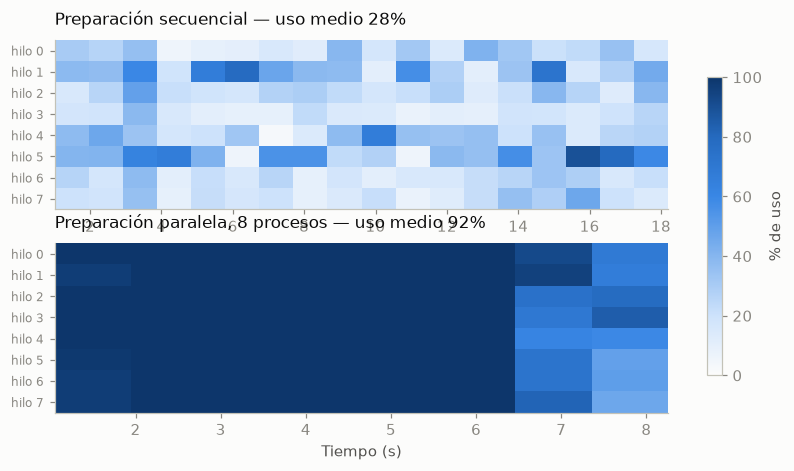

In [10]:
fig = an.mapa_nucleos({'Preparación secuencial': 'resultados/monitor/notebook_prep_secuencial.csv',
                       'Preparación paralela, 8 procesos': 'resultados/monitor/notebook_prep_paralela.csv'})
an.guardar(fig, '05_mapa_nucleos_preparacion'); plt.show()

,Variante,Procesos,Media (s),Desv. (s),Con arranque (s),Corridas,Idéntico,Speedup,Eficiencia,Imágenes/s
0,paralela,1,27.78,4.74,28.15,5,True,0.90,0.90,835.01
1,paralela,2,16.61,0.98,17.07,5,True,1.50,0.75,1396.88
2,paralela,4,12.49,1.18,13.08,5,True,1.99,0.50,1856.98
3,paralela,8,9.37,1.23,10.25,5,True,2.66,0.33,2474.83
4,secuencial,1,24.90,5.09,24.90,5,True,1.00,1.00,931.84


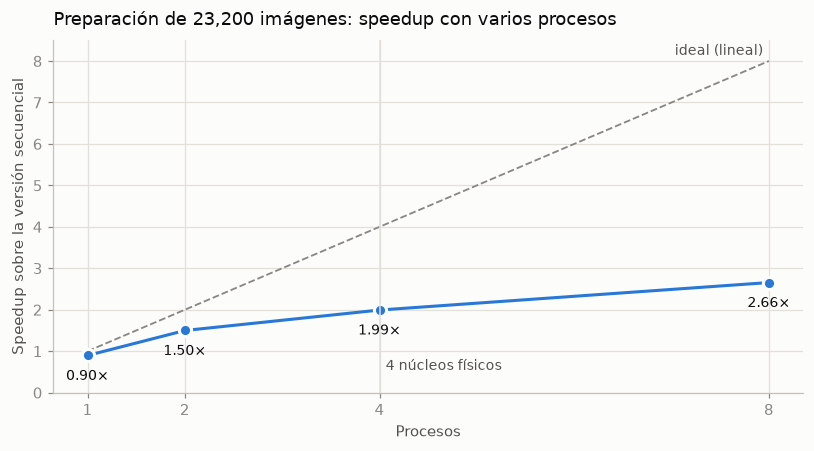

In [11]:
display(res_prep.rename(columns={'variante': 'Variante', 'procesos': 'Procesos', 'media_s': 'Media (s)',
                                 'std_s': 'Desv. (s)', 'con_arranque_s': 'Con arranque (s)', 'reps': 'Corridas',
                                 'identico': 'Idéntico', 'speedup': 'Speedup', 'eficiencia': 'Eficiencia',
                                 'imagenes_por_s': 'Imágenes/s'})
        .drop(columns=['speedup_con_arranque']).style.format(precision=2))
fig = an.grafica_escalamiento_preparacion(res_prep); an.guardar(fig, '06_escalamiento_preparacion'); plt.show()

### 5.2 Fase 2 — entrenamiento en GPU con PyTorch + cuDNN (ejecución en vivo)

Se entrenan los cuatro modelos con **las mismas reglas que el Lab 3**: 20 épocas con paciencia 4 para los modelos sin aumento y 30 épocas con paciencia 8 para los aumentados, con EarlyStopping sobre la exactitud de validación y restauración de los mejores pesos. Así el tiempo total se puede comparar con el del Lab 3 ejecutado en esta misma laptop (tabla 2.1).

Las arquitecturas son traducciones fieles de Keras (`src/modelos.py`): misma inicialización Glorot, Adam con `epsilon=1e-7` y BatchNorm con el momento de Keras.

#### Código original contra versión optimizada

La fase 2 cambia **dónde** se hace la matemática de la red, no **qué** se calcula. Primero va el código original del Lab 3 (`lab3_original/Lab3_Final.ipynb`, celdas 12, 14 y 16), copiado sin cambios: entrena en la CPU con Keras/TensorFlow. Debajo de cada bloque va su traducción en PyTorch (`src/modelos.py` y `src/entrenamiento.py`), que entrena en la GPU con cuDNN.

**1. CNN Base: original (Keras, CPU)**

```python
cnn_base = keras.Sequential([
    layers.Input(shape=FORMA_ENTRADA),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASES, activation='softmax'),
], name='CNN_Base')
```

**CNN Base: optimizada (PyTorch, GPU)**

```python
class CNNBase(nn.Module):
    def __init__(self, aumento=None, num_clases=NUM_CLASES):
        super().__init__()
        self.aumento = aumento if aumento is not None else nn.Identity()
        self.caracteristicas = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 64 -> 32
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32 -> 16
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 -> 8
        )
        self.cabeza = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_clases),          # logits: CrossEntropyLoss aplica el softmax
        )
        inicializar_como_keras(self)             # Glorot uniforme y sesgos en cero, como Keras

    def forward(self, x_nhwc):
        x = self.aumento(a_nchw(x_nhwc))         # NHWC (Keras) -> NCHW (cuDNN), dentro de la GPU
        return self.cabeza(self.caracteristicas(x))
```

**2. CNN Profunda: original (Keras, CPU)**

```python
def bloque_conv(x, filtros):
    """Bloque doble Conv-BN-ReLU seguido de reducción y dropout."""
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

entrada = layers.Input(shape=FORMA_ENTRADA)
x = entrada
for filtros in (32, 64, 128):
    x = bloque_conv(x, filtros)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
salida = layers.Dense(NUM_CLASES, activation='softmax')(x)
cnn_profunda = keras.Model(entrada, salida, name='CNN_Profunda')
```

**CNN Profunda: optimizada (PyTorch, GPU)**

```python
def bloque_conv(entrada, filtros):
    """Bloque doble Conv-BN-ReLU seguido de reducción y dropout."""
    capas = []
    for c_in in (entrada, filtros):
        capas += [nn.Conv2d(c_in, filtros, 3, padding=1, bias=False),
                  nn.BatchNorm2d(filtros, eps=1e-3, momentum=0.01),   # = BatchNormalization() de Keras
                  nn.ReLU()]
    capas += [nn.MaxPool2d(2), nn.Dropout(0.25)]
    return nn.Sequential(*capas)

class CNNProfunda(nn.Module):
    def __init__(self, aumento=None, num_clases=NUM_CLASES):
        super().__init__()
        self.aumento = aumento if aumento is not None else nn.Identity()
        self.caracteristicas = nn.Sequential(
            bloque_conv(3, 32), bloque_conv(32, 64), bloque_conv(64, 128))
        self.cabeza = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),            # GlobalAveragePooling2D
            nn.Linear(128, 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, num_clases),
        )
        inicializar_como_keras(self)
```

**3. Entrenamiento: original (Keras, CPU)**

```python
def entrenar(modelo, nombre, epocas=EPOCAS_MAX, paciencia=PACIENCIA):
    modelo.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    parada = keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=paciencia,
        restore_best_weights=True, verbose=1)
    historial = modelo.fit(X_train, y_train,
                           validation_data=(X_val, y_val),
                           epochs=epocas, batch_size=BATCH_SIZE,
                           callbacks=[parada], verbose=2)
```

**Entrenamiento: optimizado (PyTorch, GPU), extracto de `src/entrenamiento.py` y de la celda siguiente**

```python
torch.backends.cudnn.benchmark = True                     # cuDNN elige el algoritmo más rápido por capa
modelo = modelo.to('cuda')                                 # los pesos viven en la memoria de la GPU
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, eps=1e-7)   # Adam con el epsilon de Keras
Xtr, ytr = a_tensores(X_train, y_train, pinned=True)       # datos en RAM pinned: copia por DMA

for i in range(0, n, lote):                                # mismo lote de 64
    xb = Xtr[idx].pin_memory().to('cuda', non_blocking=True)   # CPU -> GPU (medido con eventos CUDA)
    yb = ytr[idx].pin_memory().to('cuda', non_blocking=True)
    optimizador.zero_grad(set_to_none=True)
    perdida = criterio(modelo(xb), yb)                     # adelante: convoluciones en cuDNN
    perdida.backward()                                     # atrás: gradientes en la GPU
    optimizador.step()                                     # Adam en la GPU
# EarlyStopping igual que Keras: val_accuracy, misma paciencia y restauración de los mejores pesos
```

Las arquitecturas son las mismas capa por capa. Lo único que cambia es lo que exige el cambio de framework: el formato del tensor, los valores por defecto de Keras que PyTorch no comparte y la salida en *logits*. La lista completa está en el docstring de `src/modelos.py`. La tercera implementación, con kernels CUDA propios en Numba, está en la sección 5.3.


In [12]:
import torch
from src.modelos import CONSTRUCTORES, contar_parametros
from src.entrenamiento import entrenar, evaluar, a_tensores
from sklearn.model_selection import train_test_split

torch.backends.cudnn.benchmark = True
torch.set_num_threads(1)   # en GPU la CPU solo arma lotes; ver la discusión en la sección 6
SEED = 42

# Misma partición estratificada 70/15/15 del Lab 3, sobre el tensor preparado en 5.1
indices = np.arange(len(y_todas))
idx_temp, idx_test = train_test_split(indices, test_size=0.15, stratify=y_todas, random_state=SEED)
idx_train, idx_val = train_test_split(idx_temp, test_size=0.15 / 0.85, stratify=y_todas[idx_temp], random_state=SEED)
X_train, y_train = X_par[idx_train], y_todas[idx_train]
X_val, y_val = X_par[idx_val], y_todas[idx_val]
X_test, y_test = X_par[idx_test], y_todas[idx_test]
del X_par
print(f"train {X_train.shape} · val {X_val.shape} · test {X_test.shape}")
print(f"GPU: {torch.cuda.get_device_name(0)} · cuDNN {torch.backends.cudnn.version()}")

REGLAS = {'CNN Base': (20, 4), 'CNN Profunda': (20, 4), 'CNN Base + Aug': (30, 8), 'CNN Profunda + Aug': (30, 8)}
modelos_gpu, historiales_gpu, tiempos_gpu = {}, {}, {}

train (16240, 64, 64, 3) · val (3480, 64, 64, 3) · test (3480, 64, 64, 3)
GPU: NVIDIA GeForce MX450 · cuDNN 91900


In [13]:
nombre = 'CNN Base'
epocas, paciencia = REGLAS[nombre]
modelo = CONSTRUCTORES[nombre]()
print(f"--- {nombre}: {contar_parametros(modelo):,} parámetros, hasta {epocas} épocas (paciencia {paciencia}) ---")
with MonitorRecursos('resultados/monitor/notebook_gpu_CNNBase.csv', 'gpu_CNNBase'):
    t0 = time.perf_counter()
    historiales_gpu[nombre] = entrenar(modelo, X_train, y_train, X_val, y_val, dispositivo='cuda',
                                       epocas=epocas, paciencia=paciencia)
    tiempos_gpu[nombre] = time.perf_counter() - t0
modelos_gpu[nombre] = modelo
print(f"--- {nombre} entrenado en {tiempos_gpu[nombre] / 60:.1f} min ({len(historiales_gpu[nombre].loss)} épocas) ---")

--- CNN Base: 1,145,693 parámetros, hasta 20 épocas (paciencia 4) ---
Época  1/20 -  10.4s (train   9.0s) | transf 0.17s cómputo 8.77s - acc 0.2120 loss 2.6841 - val_acc 0.5175 val_loss 1.5384
Época  2/20 -   8.0s (train   7.4s) | transf 0.17s cómputo 7.19s - acc 0.5709 loss 1.2856 - val_acc 0.7989 val_loss 0.6922
Época  3/20 -   8.0s (train   7.4s) | transf 0.17s cómputo 7.21s - acc 0.7517 loss 0.7356 - val_acc 0.8744 val_loss 0.4216
Época  4/20 -   8.0s (train   7.4s) | transf 0.17s cómputo 7.25s - acc 0.8231 loss 0.5151 - val_acc 0.9052 val_loss 0.3194
Época  5/20 -   8.1s (train   7.5s) | transf 0.17s cómputo 7.30s - acc 0.8613 loss 0.3933 - val_acc 0.9365 val_loss 0.2306
Época  6/20 -   8.4s (train   7.8s) | transf 0.17s cómputo 7.63s - acc 0.8914 loss 0.3202 - val_acc 0.9612 val_loss 0.1464
Época  7/20 -   8.5s (train   7.8s) | transf 0.17s cómputo 7.67s - acc 0.9150 loss 0.2460 - val_acc 0.9586 val_loss 0.1329
Época  8/20 -   8.5s (train   7.9s) | transf 0.18s cómputo 7.68s - ac

In [14]:
nombre = 'CNN Profunda'
epocas, paciencia = REGLAS[nombre]
modelo = CONSTRUCTORES[nombre]()
print(f"--- {nombre}: {contar_parametros(modelo):,} parámetros, hasta {epocas} épocas (paciencia {paciencia}) ---")
with MonitorRecursos('resultados/monitor/notebook_gpu_CNNProfunda.csv', 'gpu_CNNProfunda'):
    t0 = time.perf_counter()
    historiales_gpu[nombre] = entrenar(modelo, X_train, y_train, X_val, y_val, dispositivo='cuda',
                                       epocas=epocas, paciencia=paciencia)
    tiempos_gpu[nombre] = time.perf_counter() - t0
modelos_gpu[nombre] = modelo
print(f"--- {nombre} entrenado en {tiempos_gpu[nombre] / 60:.1f} min ({len(historiales_gpu[nombre].loss)} épocas) ---")

--- CNN Profunda: 327,933 parámetros, hasta 20 épocas (paciencia 4) ---
Época  1/20 -  39.3s (train  33.9s) | transf 0.17s cómputo 33.76s - acc 0.2971 loss 2.3080 - val_acc 0.0345 val_loss 11.2055
Época  2/20 -  30.3s (train  28.7s) | transf 0.17s cómputo 28.48s - acc 0.7327 loss 0.7888 - val_acc 0.3526 val_loss 2.1592
Época  3/20 -  30.4s (train  28.8s) | transf 0.17s cómputo 28.60s - acc 0.8786 loss 0.3751 - val_acc 0.7509 val_loss 0.6769
Época  4/20 -  30.1s (train  28.4s) | transf 0.17s cómputo 28.24s - acc 0.9288 loss 0.2264 - val_acc 0.7695 val_loss 0.6249
Época  5/20 -  30.3s (train  28.7s) | transf 0.17s cómputo 28.48s - acc 0.9530 loss 0.1531 - val_acc 0.9319 val_loss 0.1958
Época  6/20 -  30.5s (train  28.9s) | transf 0.17s cómputo 28.69s - acc 0.9673 loss 0.1098 - val_acc 0.9865 val_loss 0.0617
Época  7/20 -  30.6s (train  28.9s) | transf 0.18s cómputo 28.75s - acc 0.9705 loss 0.0946 - val_acc 0.9443 val_loss 0.1584
Época  8/20 -  30.8s (train  29.1s) | transf 0.17s cómputo 

In [15]:
nombre = 'CNN Base + Aug'
epocas, paciencia = REGLAS[nombre]
modelo = CONSTRUCTORES[nombre]()
print(f"--- {nombre}: {contar_parametros(modelo):,} parámetros, hasta {epocas} épocas (paciencia {paciencia}) ---")
with MonitorRecursos('resultados/monitor/notebook_gpu_CNNBase_Aug.csv', 'gpu_CNNBase_Aug'):
    t0 = time.perf_counter()
    historiales_gpu[nombre] = entrenar(modelo, X_train, y_train, X_val, y_val, dispositivo='cuda',
                                       epocas=epocas, paciencia=paciencia)
    tiempos_gpu[nombre] = time.perf_counter() - t0
modelos_gpu[nombre] = modelo
print(f"--- {nombre} entrenado en {tiempos_gpu[nombre] / 60:.1f} min ({len(historiales_gpu[nombre].loss)} épocas) ---")

--- CNN Base + Aug: 1,145,693 parámetros, hasta 30 épocas (paciencia 8) ---
Época  1/30 -  13.4s (train  12.7s) | transf 0.18s cómputo 12.51s - acc 0.1405 loss 3.0123 - val_acc 0.4408 val_loss 1.8575
Época  2/30 -  13.3s (train  12.5s) | transf 0.17s cómputo 12.35s - acc 0.4103 loss 1.8886 - val_acc 0.7040 val_loss 1.0313
Época  3/30 -  13.3s (train  12.6s) | transf 0.18s cómputo 12.37s - acc 0.5686 loss 1.3349 - val_acc 0.8132 val_loss 0.6518
Época  4/30 -  13.3s (train  12.5s) | transf 0.17s cómputo 12.35s - acc 0.6525 loss 1.0575 - val_acc 0.8506 val_loss 0.5125
Época  5/30 -  13.2s (train  12.5s) | transf 0.18s cómputo 12.30s - acc 0.7065 loss 0.8690 - val_acc 0.8879 val_loss 0.4040
Época  6/30 -  13.3s (train  12.5s) | transf 0.18s cómputo 12.32s - acc 0.7448 loss 0.7639 - val_acc 0.9141 val_loss 0.3038
Época  7/30 -  13.2s (train  12.5s) | transf 0.18s cómputo 12.30s - acc 0.7726 loss 0.6719 - val_acc 0.9198 val_loss 0.2585
Época  8/30 -  13.3s (train  12.5s) | transf 0.18s cómpu

In [16]:
nombre = 'CNN Profunda + Aug'
epocas, paciencia = REGLAS[nombre]
modelo = CONSTRUCTORES[nombre]()
print(f"--- {nombre}: {contar_parametros(modelo):,} parámetros, hasta {epocas} épocas (paciencia {paciencia}) ---")
with MonitorRecursos('resultados/monitor/notebook_gpu_CNNProfunda_Aug.csv', 'gpu_CNNProfunda_Aug'):
    t0 = time.perf_counter()
    historiales_gpu[nombre] = entrenar(modelo, X_train, y_train, X_val, y_val, dispositivo='cuda',
                                       epocas=epocas, paciencia=paciencia)
    tiempos_gpu[nombre] = time.perf_counter() - t0
modelos_gpu[nombre] = modelo
print(f"--- {nombre} entrenado en {tiempos_gpu[nombre] / 60:.1f} min ({len(historiales_gpu[nombre].loss)} épocas) ---")

--- CNN Profunda + Aug: 327,933 parámetros, hasta 30 épocas (paciencia 8) ---
Época  1/30 -  32.1s (train  30.4s) | transf 0.17s cómputo 30.19s - acc 0.2031 loss 2.6669 - val_acc 0.0345 val_loss 6.4662
Época  2/30 -  32.6s (train  30.8s) | transf 0.17s cómputo 30.63s - acc 0.5977 loss 1.2212 - val_acc 0.6060 val_loss 1.2254
Época  3/30 -  32.6s (train  30.8s) | transf 0.17s cómputo 30.67s - acc 0.7722 loss 0.6704 - val_acc 0.8052 val_loss 0.5356
Época  4/30 -  32.8s (train  31.0s) | transf 0.17s cómputo 30.82s - acc 0.8437 loss 0.4628 - val_acc 0.6615 val_loss 1.1131
Época  5/30 -  33.0s (train  31.2s) | transf 0.17s cómputo 31.04s - acc 0.8888 loss 0.3345 - val_acc 0.8897 val_loss 0.2864
Época  6/30 -  33.2s (train  31.4s) | transf 0.17s cómputo 31.22s - acc 0.9058 loss 0.2815 - val_acc 0.9724 val_loss 0.0907
Época  7/30 -  33.3s (train  31.5s) | transf 0.17s cómputo 31.33s - acc 0.9252 loss 0.2346 - val_acc 0.9345 val_loss 0.1672
Época  8/30 -  33.4s (train  31.6s) | transf 0.17s cóm

In [17]:
# Evaluación sobre el conjunto de prueba y comparación con el Lab 3 completo en CPU (misma laptop)
dev = torch.device('cuda')
Xt, yt = a_tensores(X_test, y_test, pinned=True)
filas = []
for nombre, modelo in modelos_gpu.items():
    torch.cuda.synchronize(); t0 = time.perf_counter()
    perdida, exactitud, _ = evaluar(modelo, Xt, yt, dev)
    torch.cuda.synchronize(); t_inf = time.perf_counter() - t0
    h = historiales_gpu[nombre]
    filas.append({'Modelo': nombre, 'Épocas GPU': len(h.loss),
                  'Minutos GPU': tiempos_gpu[nombre] / 60,
                  'Minutos CPU (Lab 3, esta laptop)': lab3_aqui.loc[nombre, 'minutos'],
                  'Épocas CPU': lab3_aqui.loc[nombre, 'epocas'],
                  's/época GPU': np.mean(h.t_epoca[1:]),
                  's/época CPU': lab3_aqui.loc[nombre, 'minutos'] * 60 / lab3_aqui.loc[nombre, 'epocas'],
                  'Exactitud GPU': exactitud, 'Exactitud CPU': lab3_aqui.loc[nombre, 'test_acc'],
                  'Inferencia GPU (s)': t_inf})
completo = pd.DataFrame(filas).set_index('Modelo')
completo['Speedup por época'] = completo['s/época CPU'] / completo['s/época GPU']
completo.to_csv('resultados/notebook_entrenamiento_completo.csv')
display(completo.style.format(precision=2).format({'Exactitud GPU': '{:.2%}', 'Exactitud CPU': '{:.2%}'}))
print(f"Entrenamiento total: CPU {completo['Minutos CPU (Lab 3, esta laptop)'].sum():.1f} min · "
      f"GPU {completo['Minutos GPU'].sum():.1f} min")

,Épocas GPU,Minutos GPU,"Minutos CPU (Lab 3, esta laptop)",Épocas CPU,s/época GPU,s/época CPU,Exactitud GPU,Exactitud CPU,Inferencia GPU (s),Speedup por época
Modelo,,,,,,,,,,
CNN Base,20,3.534882,10.000000,20,10.430092,30.000000,98.42%,98.33%,0.791392,2.876293
CNN Profunda,10,5.251318,31.900000,13,30.603834,147.230769,98.42%,97.56%,1.874583,4.810860
CNN Base + Aug,30,6.649680,18.700000,30,13.284244,37.400000,99.28%,99.17%,0.814632,2.815365
CNN Profunda + Aug,30,16.875465,50.200000,19,33.792548,158.526316,99.94%,99.40%,1.876514,4.691162


Entrenamiento total: CPU 110.8 min · GPU 32.3 min


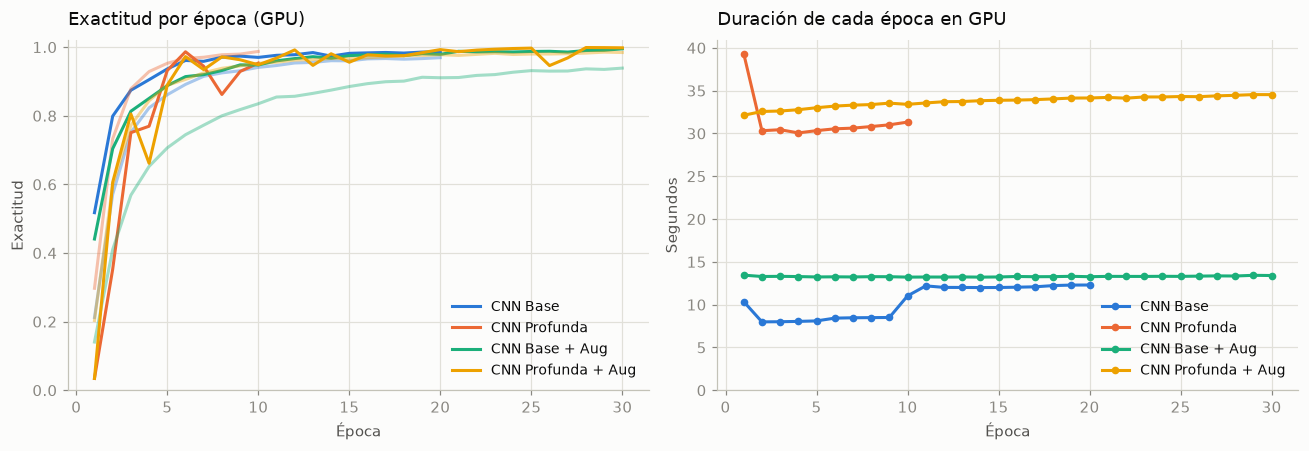

In [18]:
# Curvas de aprendizaje en GPU (línea tenue: entrenamiento; sólida: validación)
COL_MOD = dict(zip(an.ORDEN_MODELOS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for nombre, h in historiales_gpu.items():
    ep = range(1, len(h.loss) + 1)
    ejes[0].plot(ep, h.accuracy, color=COL_MOD[nombre], alpha=0.4, linewidth=2)
    ejes[0].plot(ep, h.val_accuracy, color=COL_MOD[nombre], linewidth=2, label=nombre)
    ejes[1].plot(ep, h.t_epoca, color=COL_MOD[nombre], linewidth=2, marker='o', markersize=4, label=nombre)
ejes[0].set_ylim(0, 1.02); ejes[0].set_xlabel('Época'); ejes[0].set_ylabel('Exactitud')
ejes[0].set_title('Exactitud por época (GPU)'); ejes[0].legend(fontsize=9, loc='lower right')
ejes[1].set_xlabel('Época'); ejes[1].set_ylabel('Segundos'); ejes[1].set_ylim(0, None)
ejes[1].set_title('Duración de cada época en GPU'); ejes[1].legend(fontsize=9)
plt.tight_layout(); an.guardar(fig, '07_curvas_gpu'); plt.show()

In [19]:
# Fotos propias del equipo (Ejercicio 8) con los modelos entrenados en GPU
from PIL import Image, ImageOps

def preparar_foto(ruta):
    img = ImageOps.exif_transpose(Image.open(ruta)).convert('RGB')
    lado = min(img.size); izq, arr = (img.width - lado) // 2, (img.height - lado) // 2
    return np.asarray(img.crop((izq, arr, izq + lado, arr + lado)).resize((64, 64)), dtype=np.float32) / 255.0

carpeta = os.path.join(RAIZ, 'fotos_propias')
archivos = sorted(f for f in os.listdir(carpeta) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
X_fotos = np.stack([preparar_foto(os.path.join(carpeta, f)) for f in archivos])
y_fotos = np.array([clases.index(f.split('_')[0]) for f in archivos])
Xf, yf = a_tensores(X_fotos, y_fotos, pinned=True)
print(f"{len(archivos)} fotos ({len(set(archivos))} archivos; L_alex_4 y L_daniel_3 son la misma imagen)")
for nombre, modelo in modelos_gpu.items():
    _, acc, pred = evaluar(modelo, Xf, yf, dev)
    print(f"  {nombre:<20} {acc:.2%} ({int(round(acc * len(yf)))}/{len(yf)})")

15 fotos (15 archivos; L_alex_4 y L_daniel_3 son la misma imagen)
  CNN Base             26.67% (4/15)
  CNN Profunda         60.00% (9/15)
  CNN Base + Aug       53.33% (8/15)
  CNN Profunda + Aug   53.33% (8/15)
